# Final deliverable: delivery route optimization (CVRP and CVRPTW)

**CesiCDP for the ADEME Smart Multimodal Mobility call.** Team: Pablo, Dag, Farida.

Graded deliverable, due the day before the presentation. Each section below names its owner (see
`docs/content/task-separation.md`). Keep the story first: every table or figure is followed by one
sentence saying what it means.

## 1. Data formalization  (Person 1)
> TODO: corrected version of notebook 01, section 2.

## 2. Complexity  (Person 1)
> TODO: corrected proof after tutor feedback.

## 3. Complete ILP  (Person 1)
> TODO: corrected model, CVRP and CVRPTW.

## 4. Exact approach in practice  (Person 1)
> TODO: direct solution with `cvrp.ilp` on small instances, solve time against n, LP relaxation
> as lower bound, metaheuristic as upper bound, where the exact approach stops being usable.

## 5. Chosen metaheuristic: ALNS with simulated annealing acceptance  (Person 2)
> TODO: solution encoding, neighborhood structure, destroy and repair operators, adaptive
> weights, acceptance and cooling. Follow `docs/content/technical/metaheuristic.md`.

### Simulated Annealing for the Vehicle Routing Problem 20 Instances



This notebook creates 20 reproducible synthetic VRP instances, runs a Simulated Annealing (SA) solver on each, compares against a feasible initial solution, and visualizes the results. No external datasets for now.

Assumptions : one depot; identical vehicles; every customer visited exactly once; all vehicles depart at time 0 (08:00); waiting before a customer's time window is allowed; service must start by the end of the window; vehicle capacity is hard; traffic is modeled by a time-of-departure multiplier. The cost is the sum of elapsed route durations, not merely distance. The model is an educational benchmark, not a validated road-network traffic model.

#### Imports and reproducibility
Only NumPy, pandas, and Matplotlib are required.

In [7]:
import math
import random
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MASTER_SEED = 42
N_INSTANCES = 20
print("Ready: reproducible 20-instance experiment")

Ready: reproducible 20-instance experiment


#### Mathematical model

For each used vehicle $k$, let $D_k$ denote its departure time and $R_k$ its return time. We minimize

$$\min Z = \sum_{k \in K_{\mathrm{used}}}(R_k-D_k).$$

Route simulation includes travel time affected by departure-time traffic, waiting time before the start of a time window, and customer service time. This objective is linear in the time variables, although the time-dependent travel-time relationships are not generally linear.

Feasibility : each customer is served exactly once; each vehicle load is at most $Q$; service begins inside each customer's time window; every route starts and ends at the depot.

We generate wide but finite time windows so that the initial solutions are feasible; this notebook also checks feasibility after each move.

#### Instance generation
We use 20 instances of increasing size (10 to 29 customers). The depot is node 0; customer indices are 1 to $n$. Coordinates are synthetic. Demand is in units, distance in km-like units, and time in minutes. The departure time 0 corresponds to 08:00.

In [8]:
@dataclass
class VRPInstance:
    name: str
    coords: np.ndarray
    demands: np.ndarray      
    capacity: int
    service: np.ndarray      
    tw_open: np.ndarray     
    tw_close: np.ndarray
    distance: np.ndarray
    base_minutes_per_unit: float = 1.0


def generate_instance(index, seed=MASTER_SEED):
    rng = np.random.default_rng(seed + index)
    n_customers = 10 + index  
    coords = np.vstack(([50., 50.], rng.uniform(0, 100, (n_customers, 2))))
    demands = np.r_[0, rng.integers(1, 6, size=n_customers)]
    capacity = 15
    service = np.r_[0, rng.integers(3, 9, size=n_customers)]
    tw_open = np.zeros(n_customers + 1)
    tw_close = np.full(n_customers + 1, 2000.0)
    distance = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=2)
    return VRPInstance(f"Instance_{index:02d}", coords, demands, capacity,
                       service, tw_open, tw_close, distance)

instances = [generate_instance(i) for i in range(1, N_INSTANCES + 1)]
pd.DataFrame([{"instance": x.name, "customers": len(x.demands)-1,
               "total_demand": int(x.demands.sum()), "capacity": x.capacity}
              for x in instances]).head()

,instance,customers,total_demand,capacity
0,Instance_01,11,38,15
1,Instance_02,12,42,15
2,Instance_03,13,28,15
3,Instance_04,14,56,15
4,Instance_05,15,48,15


#### Time-dependent traffic and objective evaluation
Traffic multipliers represent congestion at the departure time of each arc. For example, a multiplier of 1.6 means a trip takes 60% longer than at free-flow speed. The travel-time function is piecewise constant; this is a simplification.

A candidate route that violates capacity, visits a customer more than once, misses a customer, or starts service after a closing time is infeasible.

In [9]:
def traffic_multiplier(departure_min):
    
    hour = (8.0 + departure_min / 60.0) % 24
    if 8 <= hour < 10 or 17 <= hour < 19:
        return 1.6   
    if 10 <= hour < 16:
        return 1.15  
    return 1.0       


def evaluate_routes(routes, inst, return_details=False):
    customers = [c for route in routes for c in route]
    n = len(inst.demands) - 1
    if sorted(customers) != list(range(1, n + 1)):
        return (math.inf, None) if return_details else math.inf
    total_duration = 0.0
    details = []
    for route in routes:
        if not route:
            continue
        load = sum(inst.demands[c] for c in route)
        if load > inst.capacity:
            return (math.inf, None) if return_details else math.inf
        t = 0.0
        prev = 0
        waiting = 0.0
        travel = 0.0
        for c in route:
            drive = inst.distance[prev, c] * inst.base_minutes_per_unit * traffic_multiplier(t)
            t += drive
            travel += drive
            if t > inst.tw_close[c] + 1e-9:
                return (math.inf, None) if return_details else math.inf
            wait = max(0.0, inst.tw_open[c] - t)
            t += wait
            waiting += wait
            t += inst.service[c]
            prev = c
        back = inst.distance[prev, 0] * inst.base_minutes_per_unit * traffic_multiplier(t)
        t += back
        travel += back
        total_duration += t
        details.append({"route": route.copy(), "load": int(load),
                        "duration": t, "travel": travel, "waiting": waiting})
    return (total_duration, details) if return_details else total_duration


def initial_solution(inst):
    routes, route, load = [], [], 0
    for c in range(1, len(inst.demands)):
        d = int(inst.demands[c])
        if d > inst.capacity:
            raise ValueError("Demand exceeds capacity")
        if load + d > inst.capacity:
            routes.append(route)
            route, load = [], 0
        route.append(c)
        load += d
    if route:
        routes.append(route)
    if not math.isfinite(evaluate_routes(routes, inst)):
        raise ValueError("Initial solution infeasible: increase windows or change initialization")
    return routes

example = instances[0]
example_routes = initial_solution(example)
print(example.name, "routes:", example_routes)
print("Initial objective:", round(evaluate_routes(example_routes, example), 2), "minutes")

Instance_01 routes: [[1, 2, 3], [4, 5, 6], [7, 8, 9, 10, 11]]
Initial objective: 1132.18 minutes


#### Neighborhood operators
Randomly apply one of **2-opt** (reverse a segment within a route), **Swap** (exchange customers between routes), or **Relocate** (move one customer between routes). Reject infeasible neighbors. Empty routes are removed. A fixed number of attempts prevents infinite loops.

In [10]:
def random_neighbor(routes, inst, rng, max_attempts=80):
    for _ in range(max_attempts):
        candidate = [r.copy() for r in routes]
        operator = rng.choice(["2opt", "swap", "relocate"])
        if operator == "2opt":
            eligible = [r for r in range(len(candidate)) if len(candidate[r]) >= 2]
            if not eligible:
                continue
            r = rng.choice(eligible)
            i, j = sorted(rng.sample(range(len(candidate[r])), 2))
            candidate[r][i:j+1] = candidate[r][i:j+1][::-1]
        elif operator == "swap":
            if len(candidate) < 2:
                continue
            r1, r2 = rng.sample(range(len(candidate)), 2)
            i = rng.randrange(len(candidate[r1]))
            j = rng.randrange(len(candidate[r2]))
            candidate[r1][i], candidate[r2][j] = candidate[r2][j], candidate[r1][i]
        else:
            if len(candidate) < 2:
                continue
            r1, r2 = rng.sample(range(len(candidate)), 2)
            i = rng.randrange(len(candidate[r1]))
            customer = candidate[r1].pop(i)
            j = rng.randrange(len(candidate[r2]) + 1)
            candidate[r2].insert(j, customer)
            candidate = [r for r in candidate if r]
        if candidate != routes and math.isfinite(evaluate_routes(candidate, inst)):
            return candidate
    return [r.copy() for r in routes]

print("Neighbor example:", random_neighbor(example_routes, example, random.Random(42)))

Neighbor example: [[1, 2], [4, 5, 6], [7, 8, 3, 9, 10, 11]]


#### Simulated Annealing algorithm
At each iteration, a feasible neighbor is generated. If it is better, it is accepted. Otherwise it is accepted with probability

$$P(\mathrm{accept}) = \exp(-\Delta Z/T), \quad \Delta Z = Z_{new}-Z_{current}>0.$$

The temperature decreases geometrically: $T_{next}=\alpha T$. The algorithm returns the **best-ever solution**, not just the last accepted solution.

In [11]:
def simulated_annealing(inst, seed=42, iterations=2000, T0=100.0, alpha=0.996):
    rng = random.Random(seed)
    current = initial_solution(inst)
    current_cost = evaluate_routes(current, inst)
    best = [r.copy() for r in current]
    best_cost = current_cost
    temperature = T0
    best_history = [best_cost]
    current_history = [current_cost]
    accepted_worse = 0
    for _ in range(iterations):
        candidate = random_neighbor(current, inst, rng)
        candidate_cost = evaluate_routes(candidate, inst)
        delta = candidate_cost - current_cost
        if delta <= 0 or rng.random() < math.exp(-delta / max(temperature, 1e-12)):
            if delta > 0:
                accepted_worse += 1
            current, current_cost = candidate, candidate_cost
        if current_cost < best_cost - 1e-9:
            best, best_cost = [r.copy() for r in current], current_cost
        best_history.append(best_cost)
        current_history.append(current_cost)
        temperature = max(temperature * alpha, 1e-12)
    return {"routes": best, "cost": best_cost, "best_history": best_history,
            "current_history": current_history, "accepted_worse": accepted_worse}

one_result = simulated_annealing(example, seed=MASTER_SEED)
print("Initial:", round(evaluate_routes(example_routes, example), 2))
print("SA best:", round(one_result["cost"], 2))
print("Feasible:", math.isfinite(evaluate_routes(one_result["routes"], example)))

Initial: 1132.18
SA best: 712.28
Feasible: True


#### Run all 20 instances
Every instance has a different reproducible dataset. We use one SA run per instance here; for statistically robust comparisons, repeat each instance with multiple random seeds.

In [12]:
ITERATIONS = 2000
T0 = 100.0
ALPHA = 0.996
results = []
solutions = {}
for idx, inst in enumerate(instances, start=1):
    start_routes = initial_solution(inst)
    start_cost = evaluate_routes(start_routes, inst)
    output = simulated_annealing(inst, seed=MASTER_SEED + idx,
                                 iterations=ITERATIONS, T0=T0, alpha=ALPHA)
    final_cost = output["cost"]
    assert math.isfinite(final_cost)
    assert final_cost <= start_cost + 1e-8
    solutions[inst.name] = output
    results.append({"instance": inst.name, "customers": len(inst.demands)-1,
                    "vehicles_initial": len(start_routes),
                    "vehicles_SA": len(output["routes"]),
                    "initial_minutes": start_cost, "SA_minutes": final_cost,
                    "improvement_pct": 100*(start_cost-final_cost)/start_cost,
                    "accepted_worse": output["accepted_worse"]})

results_df = pd.DataFrame(results)
print("Completed:", len(results_df), "instances")
display(results_df.round(2))

Completed: 20 instances


,instance,customers,vehicles_initial,vehicles_SA,initial_minutes,SA_minutes,improvement_pct,accepted_worse
0,Instance_01,11,3,3,1132.18,705.76,37.66,146
1,Instance_02,12,4,3,1214.89,785.16,35.37,178
2,Instance_03,13,2,2,836.30,547.90,34.48,155
3,Instance_04,14,5,4,1353.00,813.56,39.87,202
4,Instance_05,15,4,4,1229.44,760.24,38.16,190
5,Instance_06,16,4,4,1292.01,726.31,43.78,160
6,Instance_07,17,4,4,1629.27,843.01,48.26,158
7,Instance_08,18,4,4,1400.72,849.71,39.34,166
8,Instance_09,19,5,5,1502.81,965.20,35.77,152
9,Instance_10,20,5,4,1785.11,988.22,44.64,182


#### Summary statistics and plots
The improvement is measured relative to each instance's own initial solution. Since instance sizes differ, raw costs should not be compared as if the instances were identical.

Mean improvement (%): 41.64
Median improvement (%): 40.48
Best improvement (%): 52.92
Instances improved: 20 / 20


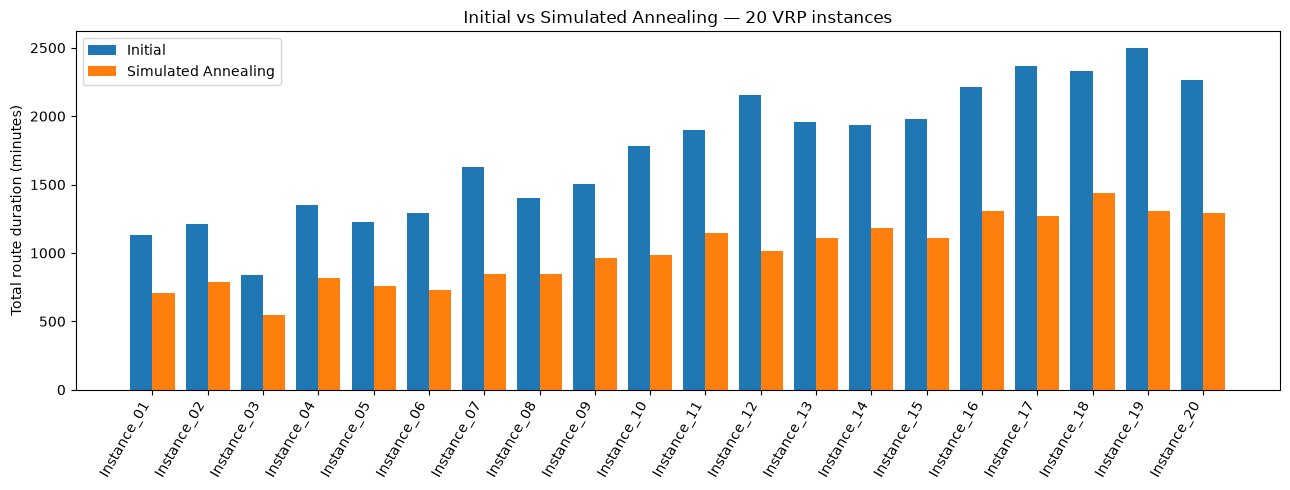

In [13]:
print("Mean improvement (%):", round(results_df.improvement_pct.mean(), 2))
print("Median improvement (%):", round(results_df.improvement_pct.median(), 2))
print("Best improvement (%):", round(results_df.improvement_pct.max(), 2))
print("Instances improved:", int((results_df.improvement_pct > 1e-8).sum()), "/", N_INSTANCES)

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(results_df))
ax.bar(x - 0.2, results_df.initial_minutes, width=0.4, label="Initial")
ax.bar(x + 0.2, results_df.SA_minutes, width=0.4, label="Simulated Annealing")
ax.set_xticks(x, results_df.instance, rotation=60, ha="right")
ax.set_ylabel("Total route duration (minutes)")
ax.set_title("Initial vs Simulated Annealing — 20 VRP instances")
ax.legend()
plt.tight_layout()
plt.show()

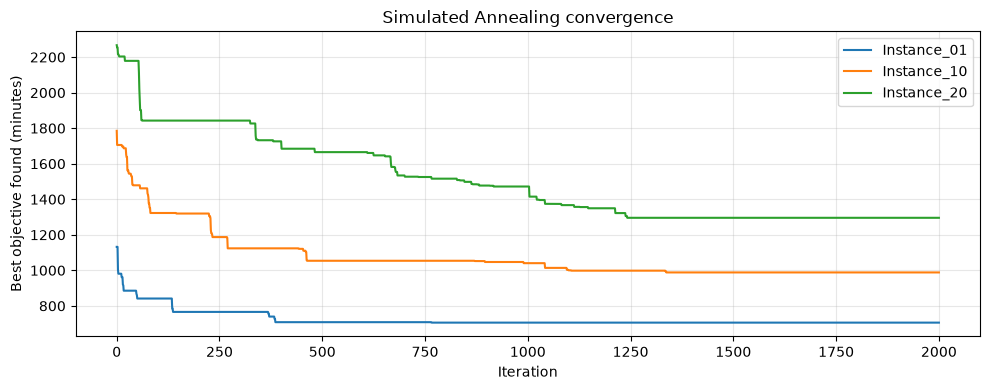

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["Instance_01", "Instance_10", "Instance_20"]:
    ax.plot(solutions[name]["best_history"], label=name)
ax.set_xlabel("Iteration")
ax.set_ylabel("Best objective found (minutes)")
ax.set_title("Simulated Annealing convergence")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Inspect a solution and visualize its routes

Instance_01 — best total duration: 705.76 minutes


,route,load,duration,travel,waiting
0,"[10, 6, 11]",11,237.08,220.08,0.0
1,"[3, 8, 1, 4]",15,215.16,195.16,0.0
2,"[9, 2, 7, 5]",12,253.53,235.53,0.0


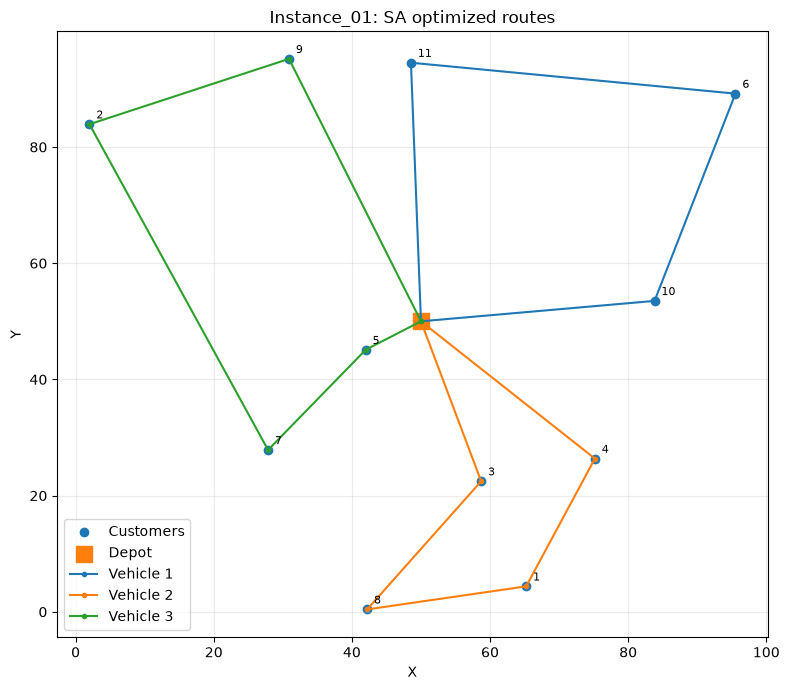

In [15]:
chosen = instances[0]
best_routes = solutions[chosen.name]["routes"]
cost, details = evaluate_routes(best_routes, chosen, return_details=True)
print(chosen.name, "— best total duration:", round(cost, 2), "minutes")
display(pd.DataFrame(details).round(2))

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(chosen.coords[1:, 0], chosen.coords[1:, 1], label="Customers")
ax.scatter(chosen.coords[0, 0], chosen.coords[0, 1], marker="s", s=130, label="Depot")
for c in range(1, len(chosen.coords)):
    ax.annotate(str(c), chosen.coords[c] + np.array([1, 1]), fontsize=8)
for r, route in enumerate(best_routes, start=1):
    points = chosen.coords[[0] + route + [0]]
    ax.plot(points[:, 0], points[:, 1], marker=".", label=f"Vehicle {r}")
ax.set_title(f"{chosen.name}: SA optimized routes")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Implementation  (Person 2)



In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))  # works without `pip install -e .`

import numpy as np
import matplotlib.pyplot as plt

from cvrp import Instance, Solution

In [ ]:
from cvrp.alns import ALNSParams, alns
from cvrp.construct import nearest_neighbor
from cvrp.neighborhoods import local_search
from cvrp.viz import plot_convergence, plot_routes

inst = Instance.random(60, capacity=100, seed=1, distribution="clustered")
start = nearest_neighbor(inst)
res = alns(inst, ALNSParams(iterations=1000), seed=1, initial=start)
best = local_search(res.best, inst)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_routes(inst, start, ax=axes[0], title=f"nearest neighbor: {start.cost(inst):.1f}")
plot_routes(inst, best, ax=axes[1], title=f"ALNS + local search: {best.cost(inst):.1f}")
plt.show()
plot_convergence(res.best_history, res.current_history); plt.show()
print("feasible:", best.is_feasible(inst), "| operator weights:", res.destroy_weights)

## 7. Test cases  (Person 2)
> TODO: point to `tests/`, show the hand-made instance where the optimum is known.

## 8. Experimental study  (Person 3)
> TODO: summary of notebook 03: design, results tables, metrics, behavior analysis.

## 9. Limitations and improvements  (all)
> TODO: what does not work yet, what we would do with two more weeks.

## 10. References
> TODO.